DAML project 1 

In [2]:
import pandas as pd 
import matplotlib.pyplot as plt 
import numpy as np 
from iminuit import cost, Minuit
from scipy import stats
from scipy.integrate import quad
from iminuit.cost import UnbinnedNLL

data = np.loadtxt('project-datafile.txt')


To fit our decay data and retrieve physical parameters we need to make some inferences to guide our analysis. 
Let's first visualise our data as a histogram. 

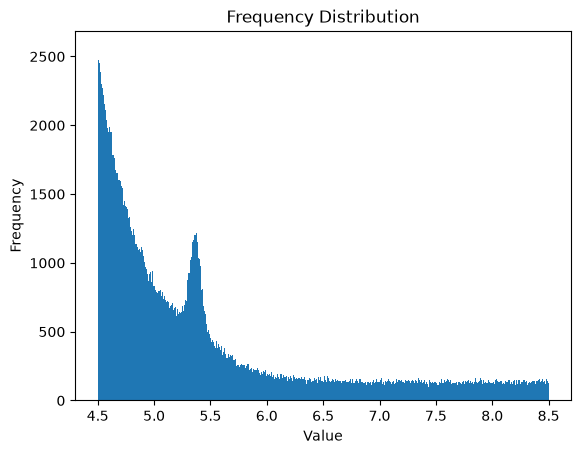

In [3]:
plt.hist(data, bins = 1000)
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.title('Frequency Distribution')
plt.show()

To fit the data we will minimise the negative log likelihood. 

Looking at the distribution we can note some features to guide our fit: 
- Overall decreasing background with a sharp inital drop off (hinting at an exponential)
- An extended flat background region from 6.5-8.5


From these we can make a good approximation that any background will need the behaviour of an exponential to account for the early peak and decreasing nature, and a linear or polynomial to account for the flat end region. The peak we will be fitted with a few physically motivated functions to be combined for an overall fit. If none of the candidates provide good fits we can return to this stage and try again.

Let's encode all of our individual functions and loop over their composite functions. 

In [4]:
fit_min = data.min()
fit_max = data.max()
data_range = fit_max - fit_min

mu_limits = (4.9, 5.9) # bound the fit to keep it in the interest region 
mu_exp = 5.4 #initial guess based on the histogram
sig_min, sig_max = 0.001, 0.5
sig0 = 0.05


def signal_raw(name, x, p):
    """
    Make an index for the models to be used to fit the signal.
    Takes inputs:
    name - name of desired function
    x - inputted data
    p - model parameters, as each model requires a different number
    Outputs:
    The desired function to be fitted.
    """
    if name == "Gaussian":
        mu, sigma = p
        return stats.norm.pdf(x, mu, sigma)

    if name == "Double Gaussian":
        mu, s1, s2, frac = p
        return frac * stats.norm.pdf(x, mu, s1) + (1 - frac) * stats.norm.pdf(x, mu, s2)

    if name == "Bifurcated Gaussian":
        mu, sl, sr = p
        sigma = np.where(x < mu, sl, sr)
        return np.exp(-0.5 * ((x - mu) / sigma)**2)

    if name == "Breit-Wigner":
        mu, gamma = p
        return stats.cauchy.pdf(x, mu, gamma)


def background_component(name, x, p):
    """
    Make an index for the models to be used to fit the background.
    Inputs and outputs are the same as for the signal.
    """
    if name == "Constant":
        return np.ones_like(x)

    if name == "Exponential":
        (rate,) = p
        return np.exp(-rate * (x - fit_min))

    if name == "Polynomial":
        c1, c2 = p
        t = (x - fit_min) / data_range # DEBUG, redefine the parameter wrt the min and max to help constrain the fit
        return (1 + c1*t + c2*t**2)**2 + 1e-12 #ensure it is never negative, and is non zero

# now we have defined our models we need to define all of our inital values and bounds,
# this looks messy as there are lots of models so lots of parameters

signals = {
    "Gaussian": (
        ["mu", "sigma"], [mu_exp, sig0],
        [mu_limits, (sig_min, sig_max)]
    ),
    "Double Gaussian": (
        ["mu", "sigma1", "sigma2", "fraction"],
        [mu_exp, sig0, min(3*sig0, sig_max*0.9), 0.7],
        [mu_limits, (sig_min, sig_max), (sig_min, sig_max), (0.01, 0.99)]
    ),
    "Bifurcated Gaussian": (
        ["mu", "sigma_left", "sigma_right"], [mu_exp, sig0, sig0],
        [mu_limits, (sig_min, sig_max), (sig_min, sig_max)]
    ),
    
    "Breit-Wigner": (
        ["mu", "gamma"], [mu_exp, sig0],
        [mu_limits, (sig_min, sig_max)]
    )
}

backgrounds = {
    "Constant + Exponential": (
        ["bg_fraction", "rate"], [0.2, 3/data_range],
        [(0.001, 0.999), (1e-8/data_range, 100/data_range)]
    ),
    "Exponential + Polynomial": (
        ["bg_fraction", "rate", "c1", "c2"], [0.5, 3/data_range, 0, 0],
        [(0.001, 0.999), (1e-8/data_range, 100/data_range), (-10, 10), (-10, 10)]
    )
}

# combine our models to get all possibilites discussed earlier on.
# exclude any background combination containing both Constant and Polynomial
model_specs = {
    f"{sname} + {bname}": {
        "signal": sname,
        "background": bname,
        "names": ["f_signal"] + s[0] + b[0],
        "start": [0.5] + s[1] + b[1],
        "limits": [(0.001, 0.999)] + s[2] + b[2]
    }
    for sname, s in signals.items()
    for bname, b in backgrounds.items()
    if not ("Polynomial" in bname and "Constant" in bname)
}

print(f"Models: {len(model_specs)}")


Models: 8


Now we can perform the fits for each combination, plot them for sanity and return our physical parameters

In [25]:
fit_results = []
fit_functions = {}

# normalise the pdf 
def normalise_pdf(function):
    norm = quad(function, fit_min, fit_max)[0]
    return lambda x: function(x) / norm

def make_model_pdf(spec):
    signal_name = spec["signal"]
    background_name = spec["background"]
    signal_names = signals[signal_name][0]
    background_names = backgrounds[background_name][0]
    components = background_name.split(" + ")

    def pdf(x, *values):
        # convert to a dictionary so items can be retrieved by name
        p = dict(zip(spec["names"], values))

        signal_params = [p[name] for name in signal_names]
        signal = normalise_pdf(lambda t: signal_raw(signal_name, t, signal_params))(x)

        background_pdfs = []
        for component in components:
            if component == "Constant":
                params = []
            elif component == "Exponential":
                params = [p["rate"]]
            else:
                params = [p["c1"], p["c2"]]

            background_pdfs.append(normalise_pdf(
                lambda t: background_component(component, t, params)
            )(x))

        background = p["bg_fraction"] * background_pdfs[0]
        background += (1 - p["bg_fraction"]) * background_pdfs[1]

        return p["f_signal"] * signal + (1 - p["f_signal"]) * background # make our composite functions

    return pdf

minimisers = {} # dictionary for the covariance matrices 

for model_name, spec in model_specs.items():
    print(f"Fitting: {model_name}")

    pdf = make_model_pdf(spec)
    fit_functions[model_name] = pdf

    minimiser = Minuit(UnbinnedNLL(data, pdf),*spec["start"],name=spec["names"])
    minimiser.limits = spec["limits"]
    minimiser.migrad()
    minimiser.hesse()
    minimisers[model_name] = minimiser

    result = {"Model": model_name, "NLL": minimiser.fval}

    for name in spec["names"]:
        result[name] = minimiser.values[name]
        result[f"{name}_err"] = minimiser.errors[name]

    fit_results.append(result)

results_df = pd.DataFrame(fit_results) # collect all results into a neat pandas df, covariance errors will be needed later 


Fitting: Gaussian + Constant + Exponential
Fitting: Gaussian + Exponential + Polynomial
Fitting: Double Gaussian + Constant + Exponential
Fitting: Double Gaussian + Exponential + Polynomial
Fitting: Bifurcated Gaussian + Constant + Exponential
Fitting: Bifurcated Gaussian + Exponential + Polynomial
Fitting: Breit-Wigner + Constant + Exponential
Fitting: Breit-Wigner + Exponential + Polynomial


Once those fits have completed we must visually check them, this allows us to remove any that are clearly incorrect or rerun any with tweaked initalisations.

/var/folders/ys/fx_3y_355hx3vplv5_2klwsw0000gn/T/ipykernel_97544/642162390.py:23: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[row, column].legend(fontsize=8)


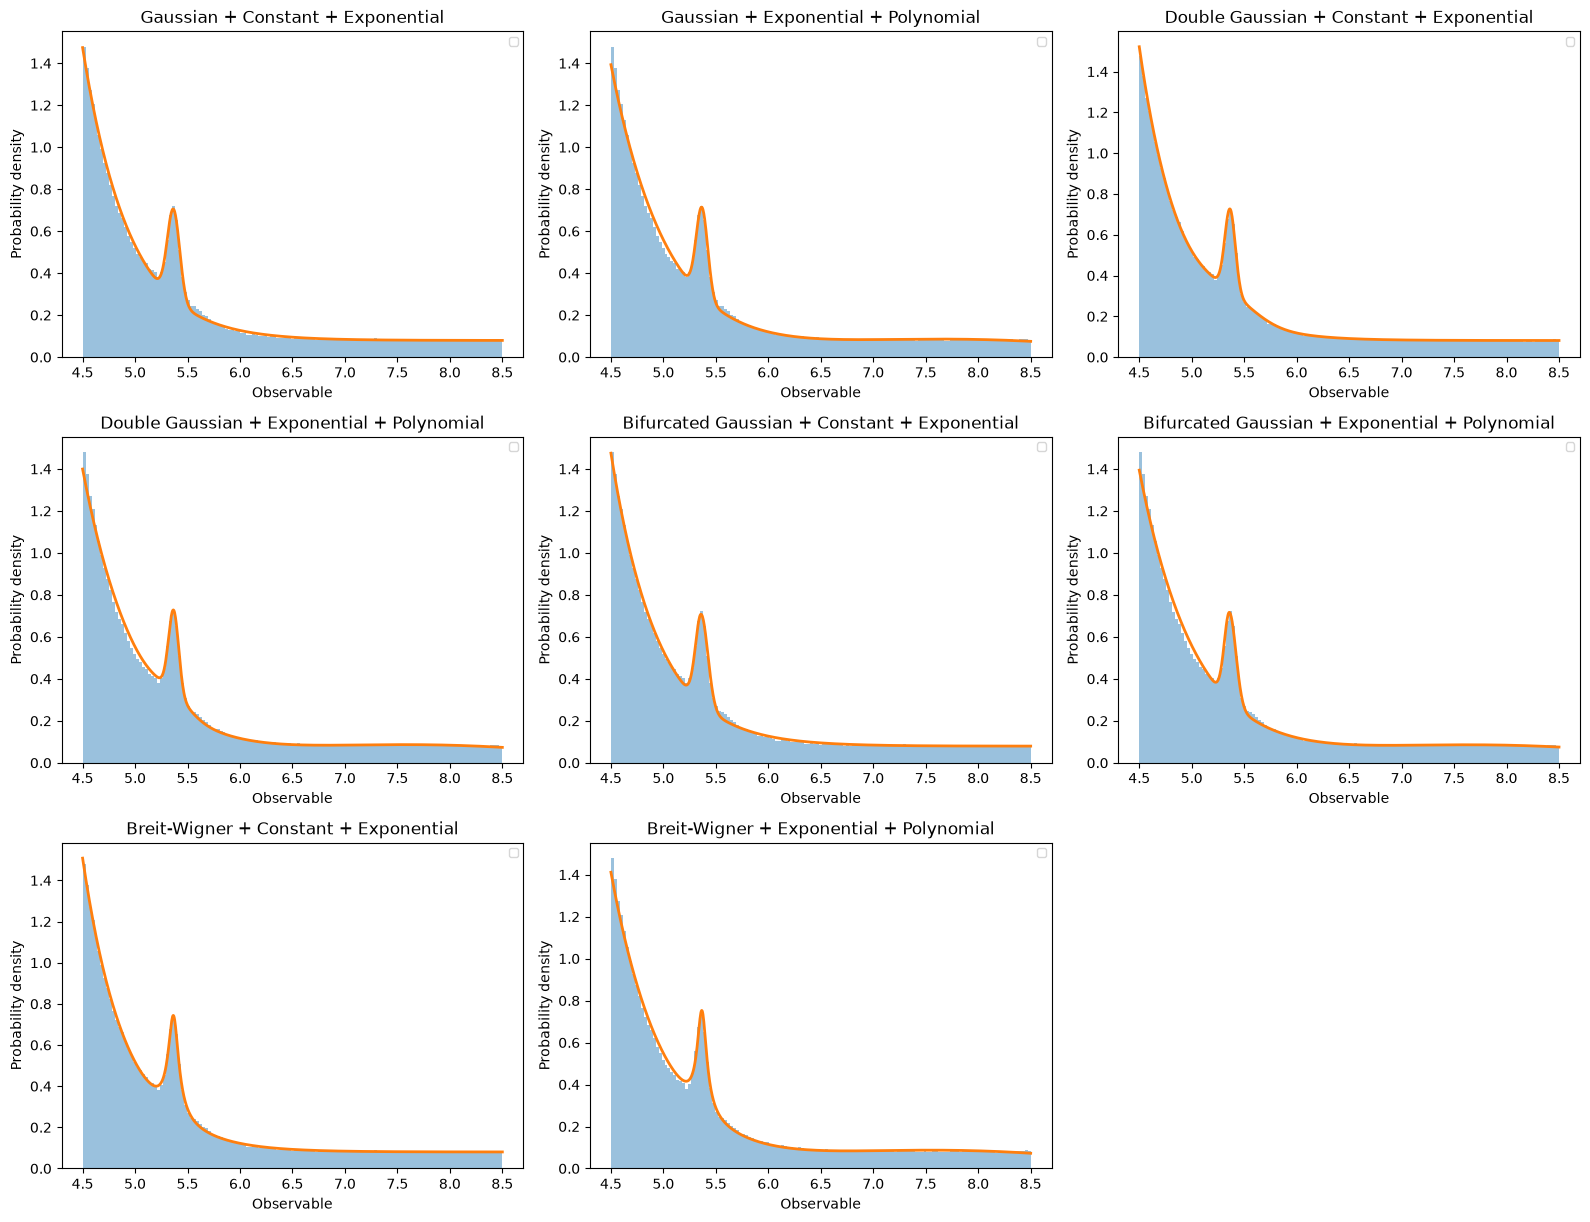

In [ ]:
x_plot = np.linspace(fit_min, fit_max, 1000)
fig, axes = plt.subplots(5, 3, figsize=(16, 20))
plot_number = 0

for row in range(5):  # loop over to make a compact plot grid to visualise the fits
    for column in range(3):
        if plot_number < len(fit_results):

            name = fit_results[plot_number]["Model"]
            record = fit_results[plot_number]

            pars = []
            for p in model_specs[name]["names"]:
                pars.append(record[p])

            axes[row, column].hist(data, bins="auto",range=(fit_min, fit_max), density=True, alpha=0.45,)
            axes[row, column].plot(x_plot, fit_functions[name](x_plot, *pars), linewidth=2,)
            axes[row, column].set_title(name)
            axes[row, column].set_xlabel("Observable")
            axes[row, column].set_ylabel("Probability density")
            axes[row, column].legend(fontsize=8)
            plot_number = plot_number + 1

        else:
            axes[row, column].set_visible(False)

plt.tight_layout()
plt.show()


Now we have our candidate fits we can check the parameters they give and the associated errors from minuit. 

In [24]:
for result in fit_results:
    print(f'{result["Model"]}: Mass = {result["mu"]:.5f} ± {result["mu_err"]:.5f}, Signal Fraction = {result["f_signal"]:.5f} ± {result["f_signal_err"]:.5f}')

Gaussian + Constant + Exponential: Mass = 5.36632 ± 0.00066, Signal Fraction = 0.06307 ± 0.00071
Gaussian + Exponential + Polynomial: Mass = 5.36729 ± 0.00066, Signal Fraction = 0.05811 ± 0.00067
Double Gaussian + Constant + Exponential: Mass = 5.36524 ± 0.00066, Signal Fraction = 0.09878 ± 0.00249
Double Gaussian + Exponential + Polynomial: Mass = 5.36718 ± 0.00065, Signal Fraction = 0.06808 ± 0.00140
Bifurcated Gaussian + Constant + Exponential: Mass = 5.36167 ± 0.00182, Signal Fraction = 0.06309 ± 0.00071
Bifurcated Gaussian + Exponential + Polynomial: Mass = 5.36111 ± 0.00168, Signal Fraction = 0.05829 ± 0.00067
Breit-Wigner + Constant + Exponential: Mass = 5.36568 ± 0.00066, Signal Fraction = 0.09107 ± 0.00118
Breit-Wigner + Exponential + Polynomial: Mass = 5.36732 ± 0.00065, Signal Fraction = 0.08141 ± 0.00109


Minuit returns errors as the diagonal elements in the covariance matrix. Off diagonal elements represent correlation between parameters and should not be simply ignored as if two parameters are strongly correlated then multiple combinations of their values may be a good description of the data making it hard to ressolve their true individual contributions

In [26]:
for model_name, minimiser in minimisers.items():

    corr = minimiser.covariance.correlation()
    parameters = minimiser.parameters

    correlations = []

    for i in range(len(parameters)):
        for j in range(i + 1, len(parameters)):

            correlations.append({
                "Model": model_name,
                "Parameter 1": parameters[i],
                "Parameter 2": parameters[j],
                "Correlation": corr[i, j]
            })

    correlations.sort(
        key=lambda x: abs(x["Correlation"]),
        reverse=True
    )

    print(f"\n{model_name}")

    for result in correlations[:5]:
        print(
            f'{result["Parameter 1"]} - '
            f'{result["Parameter 2"]}: '
            f'{result["Correlation"]:.3f}'
        )


Gaussian + Constant + Exponential
bg_fraction - rate: 0.600
f_signal - sigma: 0.560
f_signal - rate: 0.423
sigma - rate: 0.328
f_signal - bg_fraction: 0.286

Gaussian + Exponential + Polynomial
bg_fraction - rate: -0.635
bg_fraction - c2: -0.543
f_signal - sigma: 0.527
rate - c2: 0.511
f_signal - rate: 0.370

Double Gaussian + Constant + Exponential
f_signal - rate: 0.874
bg_fraction - rate: 0.808
f_signal - sigma2: 0.742
f_signal - fraction: -0.729
f_signal - bg_fraction: 0.712

Double Gaussian + Exponential + Polynomial
bg_fraction - rate: -0.782
f_signal - rate: 0.724
sigma2 - fraction: -0.679
f_signal - bg_fraction: -0.661
f_signal - sigma1: 0.655

Bifurcated Gaussian + Constant + Exponential
mu - sigma_left: 0.860
mu - sigma_right: -0.780
bg_fraction - rate: 0.599
sigma_left - sigma_right: -0.568
f_signal - rate: 0.423

Bifurcated Gaussian + Exponential + Polynomial
mu - sigma_left: 0.816
mu - sigma_right: -0.809
c1 - c2: -0.652
bg_fraction - rate: -0.640
sigma_left - sigma_right

 Residuals provide an important model to data comparison. The ideal residual plot should be a random scatter above and below zero reflecting that the model is representative of the underlying distribution with some error.

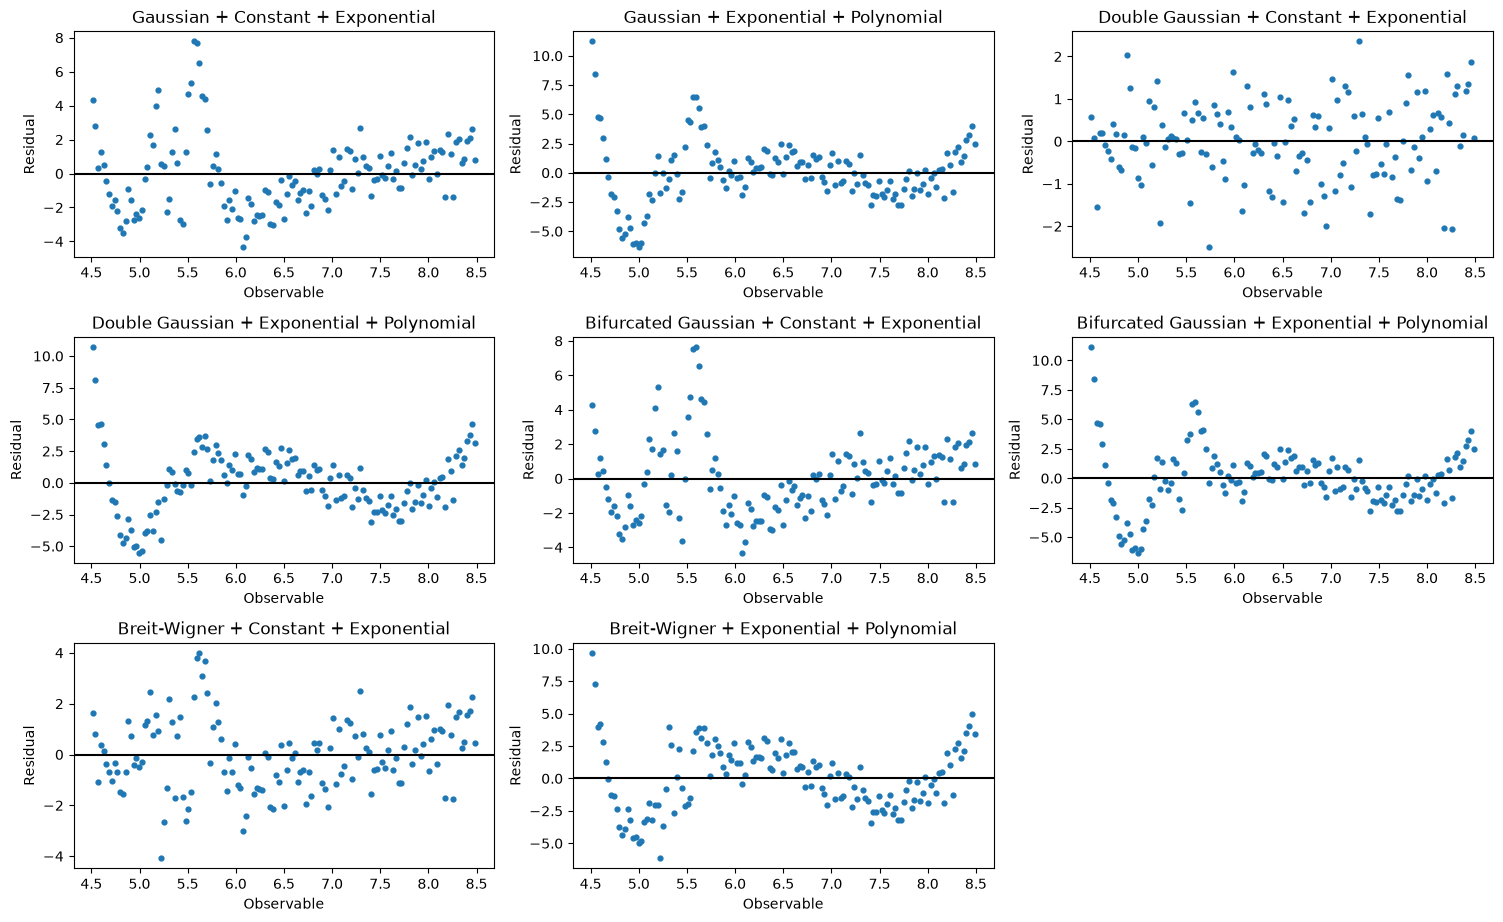

In [16]:
counts, bin_edges = np.histogram(data, bins="auto", range=(fit_min, fit_max))

bin_centres = (bin_edges[:-1] + bin_edges[1:]) / 2 # define our bin centres

model_names = []
for f in fit_results:
    model_names.append(f["Model"])

fig, axes = plt.subplots(5, 3, figsize=(15, 15))
axes = axes.flatten()

for i in range(len(model_names)):

    name = model_names[i]
    record = fit_results[i]

    pars = []
    for p in model_specs[name]["names"]:
        pars.append(record[p])

    pdf = fit_functions[name]

    expected = []
    for j in range(len(counts)): # we must loop over the bins as our fit is continuous but our data is discrete
        x = np.linspace(bin_edges[j], bin_edges[j+1], 101)
        expected.append(len(data) * np.trapezoid(pdf(x, *pars), x)) # integrate to find an expected number of the continuous pdf per bin

    expected = np.array(expected)

    residuals = (counts - expected) / np.sqrt(expected)

    axes[i].axhline(0, color="black")
    axes[i].scatter(bin_centres, residuals, s=12)
    axes[i].set_title(name)
    axes[i].set_xlabel("Observable")
    axes[i].set_ylabel("Residual")

for i in range(len(model_names), len(axes)):
    axes[i].set_visible(False)

plt.tight_layout()
plt.show()


Here we see some interesting results, many of the fits show strong relationships within the residual plots. Possibly the most telling of all is the sharp systematic decrease around 5, this is where our peak was - we infer that a model with large sytematic residual at the the peak is nto capturing core peak features. These plots show one clear best fit, the Double Gaussian + Constant + Exponential  

A further statistical check we can use is toys. Toys are a set of simulated datasets from our fitted PDF's, we can then refit these to check whether they reproduce the PDF parameters. The toy parameters and fitted parameters can reveal biases in the fit

In [ ]:
accepted_models = results_df # let's run all models 

toy_results = []
n_toys = 200

for _, row in accepted_models.iterrows():
    model_name = row["Model"]
    spec = model_specs[model_name]
    pdf = fit_functions[model_name]
    true_values = [row[p] for p in spec["names"]]

    x = np.linspace(fit_min, fit_max, 10000)
    probabilities = pdf(x, *true_values)
    probabilities /= probabilities.sum()

    for i in range(n_toys):
        toy = np.random.choice(x, size=len(data), p=probabilities)

        minimiser = Minuit(
            UnbinnedNLL(toy, pdf), *true_values, name=spec["names"])
        minimiser.limits = spec["limits"]
        minimiser.migrad()
        minimiser.hesse()

        result = {"Model": model_name, "Iteration": i, "Valid": minimiser.valid}

        for name in spec["names"]:
            result[name] = minimiser.values[name]
            result[f"{name}_err"] = minimiser.errors[name]

        toy_results.append(result)

toy_results_df = pd.DataFrame(toy_results)


# Lets do some stats on the results and store them seperately so we can comapre the models more easily

summary_rows = []

for _, row in accepted_models.iterrows():

    model_name = row["Model"]
    spec = model_specs[model_name]

    model_toys = toy_results_df[
        toy_results_df["Model"] == model_name
    ]

    # Only use successful fits for parameter statistics
    valid_toys = model_toys[model_toys["Valid"]]

    success_rate = model_toys["Valid"].mean()

    for parameter in spec["names"]:

        true_value = row[parameter]

        fitted_values = valid_toys[parameter].dropna()
        uncertainties = valid_toys[f"{parameter}_err"].dropna()

        # Calculate our classical stats
        mean_fitted = fitted_values.mean()
        bias = mean_fitted - true_value
        variance = fitted_values.var(ddof=0)
        std_deviation = fitted_values.std(ddof=0)
        mean_uncertainty = uncertainties.mean()

        # Pull distribution
        pulls = (fitted_values - true_value) / valid_toys.loc[fitted_values.index, f"{parameter}_err"]
        pulls = pulls.replace([np.inf, -np.inf], np.nan).dropna()
        pull_mean = pulls.mean()
        pull_width = pulls.std(ddof=0)

        summary_rows.append({
            "Model": model_name,
            "Parameter": parameter,
            "True value": true_value,
            "Mean fitted": mean_fitted,
            "Bias": bias,
            "Variance": variance,
            "Std deviation": std_deviation,
            "Mean uncertainty": mean_uncertainty,
            "Pull mean": pull_mean,
            "Pull width": pull_width,
            "Success rate": success_rate
        })

# Create summary dataframe
summary_df = pd.DataFrame(summary_rows)


print(summary_df)

                                             Model    Parameter  True value  \
0                Gaussian + Constant + Exponential     f_signal    0.063072   
1                Gaussian + Constant + Exponential           mu    5.366316   
2                Gaussian + Constant + Exponential        sigma    0.058880   
3                Gaussian + Constant + Exponential  bg_fraction    0.338708   
4                Gaussian + Constant + Exponential         rate    2.251401   
5              Gaussian + Exponential + Polynomial     f_signal    0.058105   
6              Gaussian + Exponential + Polynomial           mu    5.367289   
7              Gaussian + Exponential + Polynomial        sigma    0.055056   
8              Gaussian + Exponential + Polynomial  bg_fraction    0.808350   
9              Gaussian + Exponential + Polynomial         rate    1.817750   
10             Gaussian + Exponential + Polynomial           c1  -10.000000   
11             Gaussian + Exponential + Polynomial  

So now we have generated multiple simulated experiments. These simulations will be used to determine bias in the fit. 